# Animación de gráficos de barras

[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fralfaro/dataviz/blob/main/animaciones/ANIMATE_BAR_CHARTS/animate_bar_charts.ipynb)

Explora cómo animar barras, actualizar variables HSL y construir una visualización de barras con transiciones suaves.

**Qué aprenderás:** usar primitivas de Manim, controlar escenas con clases y leer el código de animación paso a paso.

## Cómo usar este notebook

1. Abre el notebook en Google Colab con el botón superior.
2. Ejecuta primero la celda de instalación y reinicia el entorno si Colab lo solicita.
3. Ejecuta después las escenas de Manim de forma individual para renderizar cada animación.
4. Cambia parámetros, colores o fórmulas y vuelve a ejecutar la escena para experimentar.

Manim renderiza los videos dentro de la salida de la celda mediante su magia de Jupyter. Los archivos del repositorio se mantienen como ejemplos didácticos; revisa cada escena antes de reutilizarla en un proyecto propio.

Repositorio: [https://github.com/fralfaro/dataviz](https://github.com/fralfaro/dataviz)

## 1. Instalación y preparación

Ejecuta esta celda una sola vez por sesión de Colab. Incluye Manim, soporte de Cairo/LaTeX y las dependencias usadas por los ejemplos.

In [1]:
# Dependencias para ejecutar Manim en Google Colab.
# La celda sigue la guía oficial de instalación de Manim para Colab.
!sudo apt-get update -qq
!sudo apt-get install -y -qq libcairo2-dev texlive texlive-latex-extra texlive-fonts-extra texlive-latex-recommended texlive-science tipa libpango1.0-dev
!pip install -q manim mpmath IPython==8.21.0

# Si Colab solicita reiniciar el entorno de ejecución, hazlo y vuelve a ejecutar desde aquí.


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 3. Escenas y conceptos

Las siguientes celdas contienen la configuración, las definiciones de escena y los renders interactivos.

In [2]:
# Paso 1: código de la escena o experimento.

from manim import *
config.media_embed = True
config.media_width = "100%"
config.disable_caching = True
_RF = "-qm -v WARNING"

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


# Animate BarChart

Manim Community v0.21.0

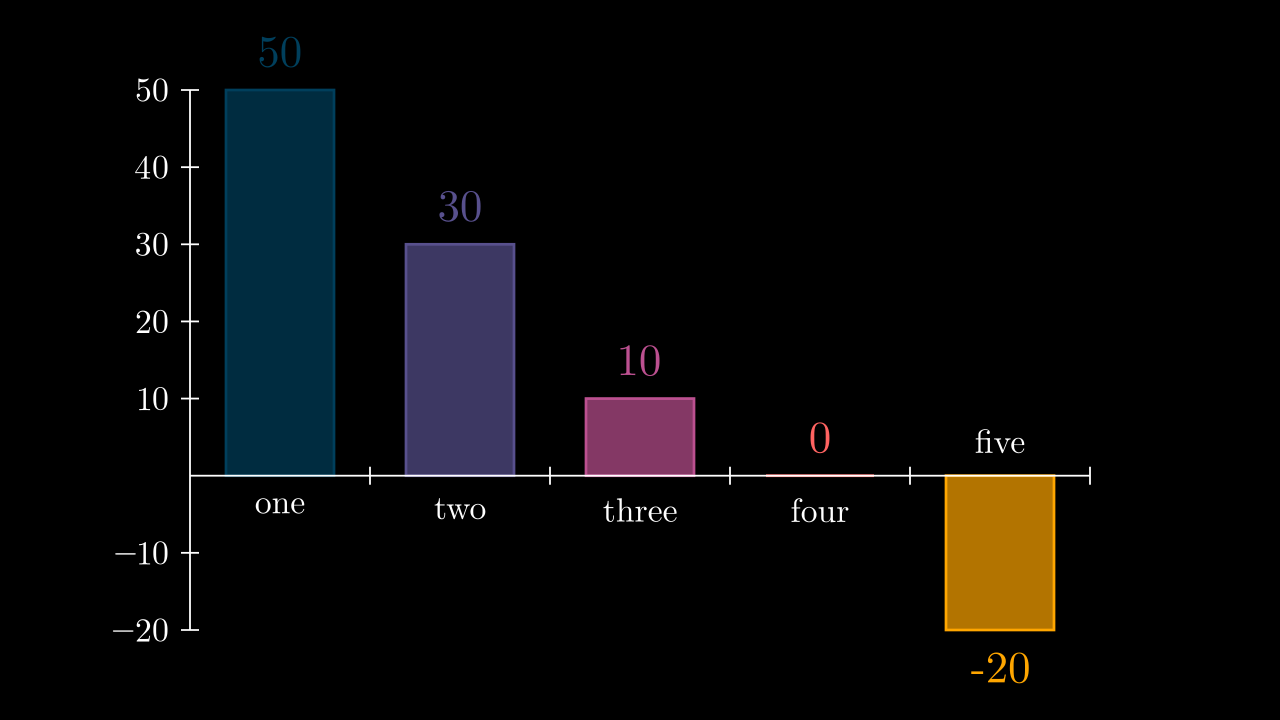

In [3]:
# Paso 3: código de la escena o experimento.

class Example(Scene):
  def construct(self):
    chart = BarChart(
      values=[50, 30, 10, 0, -20],
      bar_names=["one", "two", "three", "four", "five"],
      y_range=[-20, 50, 10],
      y_length=6,
      x_length=10,
      x_axis_config={"font_size": 36},
    )

    c_bar_lbls = chart.get_bar_labels(font_size=48)
    self.add(chart, c_bar_lbls)

%manim $_RF Example

In [4]:
# Paso 4: código de la escena o experimento.

class Example(Scene):
  def construct(self):
    chart = BarChart(
      values=[50, 30, 10, 0, -20],
      # bar_names=["one", "two", "three", "four", "five"],
      y_range=[-20, 50, 10],
      y_length=6,
      x_length=10,
      x_axis_config={"font_size": 36},
    )

    self.add(chart)
    self.wait()
    chart.change_bar_values([-20, 0, 10, 30, 50])
    self.wait()

%manim $_RF Example

Manim Community v0.21.0

## Test colors

In [5]:
# Paso 6: código de la escena o experimento.

def get_hsl_color(h, s, l):
  v = l + s * min(l, 1-l)
  s = 0 if v == 0 else 2 * (1-l/v)
  return ManimColor.from_hsv([h, s, v])

In [6]:
# Paso 7: código de la escena o experimento.

class Example(Scene):
  def construct(self):
    hsl_variables = VGroup(
      Variable(0, "h"),
      Variable(0.5, "s"),
      Variable(0.5, "l"),
    ).arrange(DOWN, aligned_edge=LEFT).to_edge(LEFT)
    sq = Square(3, fill_opacity=1)

    h_tr = hsl_variables[0].tracker
    s_tr = hsl_variables[1].tracker
    l_tr = hsl_variables[2].tracker

    sq.add_updater(
      lambda mob: mob.set_color(
        get_hsl_color(
          h_tr.get_value(),
          s_tr.get_value(),
          l_tr.get_value(),
        )
      ),
      call_updater=True
    )

    self.add(hsl_variables, sq)
    self.play(
      h_tr.animate.set_value(1),
      run_time=4
    )
    self.wait()
    self.play(
      h_tr.animate.set_value(0.2),
      s_tr.animate.set_value(0.31),
      l_tr.animate.set_value(0.63),
      run_time=3
    )
    self.wait()

%manim $_RF Example

Manim Community v0.21.0

## HSL animation

Manim Community v0.21.0

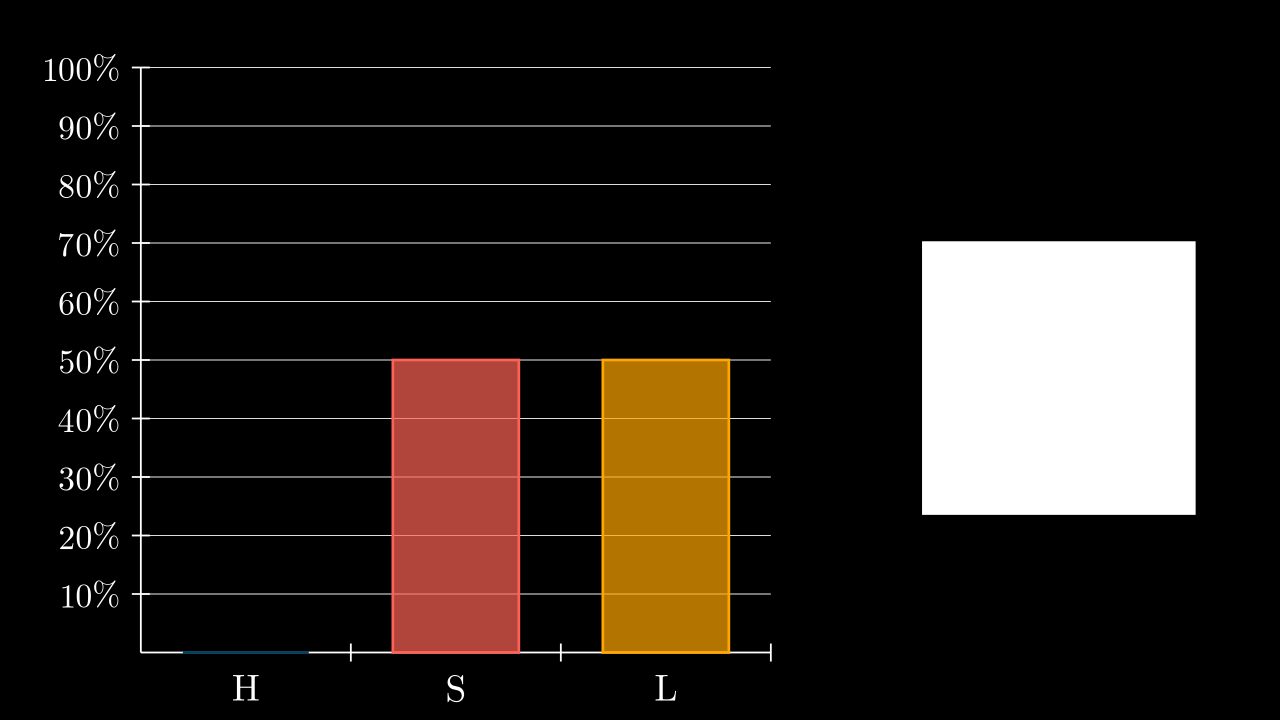

In [7]:
# Paso 9: código de la escena o experimento.

class AbstractScene(Scene):
  def setup(self):
    chart = BarChart(
      values=[0, 50, 50],
      y_range=[0, 100, 10],
      y_length=6.5,
      x_length=7,
      x_axis_config={"font_size": 40},
      bar_names=["H", "S", "L"],
      y_axis_config={
        "decimal_number_config":{
          "unit": "\\%",
          "num_decimal_places": 0
        }
      }
    ).to_edge(LEFT)

    h_lines = VGroup(*[
      Line(chart.c2p(0, x), chart.c2p(3, x), stroke_width=1)
      for x in range(0,110,10)
    ])

    sq = Square(3, fill_opacity=1).next_to(chart, RIGHT, buff=1.7)

    h_r, s_r, l_r = chart.bars
    s_r.set_color(RED)

    self.add(chart, h_lines, sq, *chart.bars)
    self.chart   = chart
    self.sq      = sq
    self.h_lines = h_lines

class Example(AbstractScene):
  pass

%manim $_RF Example

In [8]:
# Paso 10: código de la escena o experimento.

class Example(AbstractScene):
  def construct(self):
    chart = self.chart
    sq = self.sq
    
    hsl_variables = VGroup(
      DecimalNumber(0),
      DecimalNumber(50),
      DecimalNumber(50),
    )

    h_dn, s_dn, l_dn = hsl_variables

    sq.add_updater(
      lambda mob: mob.set_color(
        get_hsl_color(
          h_dn.get_value() / 100,
          s_dn.get_value() / 100,
          l_dn.get_value() / 100,
        )
      ),
      call_updater=True
    )

    def chart_updater(mob:BarChart):
      hb, sb, lb = mob.bars
      mob.change_bar_values([
        h_dn.get_value(), s_dn.get_value(), l_dn.get_value()
      ])
      h_dn.next_to(hb, UP, buff=0.1)
      s_dn.next_to(sb, UP, buff=0.1)
      l_dn.next_to(lb, UP, buff=0.1)
    
    chart.add_updater(chart_updater, call_updater=True)

    self.add(chart, sq, hsl_variables)
    self.play(
      ChangeDecimalToValue(h_dn, 100),
      # Don't use: h_dn.animate.set_value(100)
      run_time=4
    )
    self.wait()
    self.play(
      ChangeDecimalToValue(h_dn, 20),
      ChangeDecimalToValue(s_dn, 31),
      ChangeDecimalToValue(l_dn, 63),
      run_time=3
    )
    self.wait()

%manim $_RF Example

Manim Community v0.21.0